In [9]:
import pandas as pd

# 1. Load the brand new Inshorts dataset locally
file_path = r"D:\Internship\Week_3_project\Data\inshort_news_dataset.csv"
df = pd.read_csv(file_path)

print("\n" + "="*50 + "\n")

# 2. Inspect the structure and columns
print(" Task 1: Dataset Verification ")
print(f"Total News Articles: {df.shape[0]}")
print(f"Exact Column Names: {df.columns.tolist()}\n")

print(" Structural Feature Data Types ")
df.info()

print("\n Visual Text Sample ")
display(df.head())



 Task 1: Dataset Verification 
Total News Articles: 307696
Exact Column Names: ['Headline', 'Content', 'News Categories', 'Date']

 Structural Feature Data Types 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307696 entries, 0 to 307695
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Headline         307696 non-null  object
 1   Content          307696 non-null  object
 2   News Categories  307696 non-null  object
 3   Date             307696 non-null  object
dtypes: object(4)
memory usage: 9.4+ MB

 Visual Text Sample 


,Headline,Content,News Categories,Date
0,Congress leader Baljinder Singh shot dead at h...,Congress leader Baljinder Singh was shot dead ...,['national'],19-09-2023
1,17-year-old girl preparing for NEET dies by su...,Another NEET aspirant died by suicide in Rajas...,['national'],19-09-2023
2,Hampers to welcome MPs in new Parliament tomor...,In order to mark the first-ever working day of...,['national'],19-09-2023
3,"Only 10% women lawmakers in RS, while only 14%...","Congress President Mallikarjun Kharge, while s...",['national'],19-09-2023
4,"Ganesh temple decorated with notes, coins wort...",The Sri Sathya Ganapathi Temple in Bengaluru a...,['national'],19-09-2023


In [12]:
import pandas as pd
import re

# 1. Create a smaller dataframe with just the necessary columns to save memory
nlp_df = df[['Content', 'News Categories']].copy()

# 2. Define the text cleaning function
def clean_text(text):
    # Ensure the input is a string to prevent errors with missing data
    if not isinstance(text, str):
        return ""
    
    # Convert text to lowercase
    text = text.lower()
    
    # Remove everything except lowercase letters (a-z) and spaces (\s)
    text = re.sub(r'[^a-z\s]', '', text)
    
    # Optional: remove extra continuous whitespaces created by removing punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# 3 & 4. Print status and apply the function to create 'cleaned_content'
print("Applying text cleaning to Content column (this may take 10-20 seconds)...")
nlp_df['cleaned_content'] = nlp_df['Content'].apply(clean_text)

# 5. Clean up the 'News Categories' column (lowercase and strip whitespaces)
nlp_df['News Categories'] = nlp_df['News Categories'].str.lower().str.strip()

# 6. Print the number of unique categories
unique_categories = nlp_df['News Categories'].nunique()
print(f"Number of unique news categories: {unique_categories}")
print("-" * 50)

# 7. Display the original and cleaned content side-by-side
print(nlp_df[['Content', 'cleaned_content']].head())


Applying text cleaning to Content column (this may take 10-20 seconds)...
Number of unique news categories: 1335
--------------------------------------------------
                                             Content  \
0  Congress leader Baljinder Singh was shot dead ...   
1  Another NEET aspirant died by suicide in Rajas...   
2  In order to mark the first-ever working day of...   
3  Congress President Mallikarjun Kharge, while s...   
4  The Sri Sathya Ganapathi Temple in Bengaluru a...   

                                     cleaned_content  
0  congress leader baljinder singh was shot dead ...  
1  another neet aspirant died by suicide in rajas...  
2  in order to mark the firstever working day of ...  
3  congress president mallikarjun kharge while sp...  
4  the sri sathya ganapathi temple in bengaluru a...  


In [14]:
# 1. Find the top 10 most frequent categories
top_10_categories = nlp_df['News Categories'].value_counts().head(10).index

# 2. Filter nlp_df to only keep rows where the category is in the top 10 list
nlp_df = nlp_df[nlp_df['News Categories'].isin(top_10_categories)]

# 3. Print the new shape of the dataframe to see how many articles were retained
print(f"New shape after filtering: {nlp_df.shape}")
print("-" * 50)

# 4. Print the value_counts() of the remaining categories to verify the final targets
print("Final 10 Target Categories:")
print(nlp_df['News Categories'].value_counts())


New shape after filtering: (116982, 3)
--------------------------------------------------
Final 10 Target Categories:
News Categories
['entertainment']               16728
['miscellaneous']               13691
['science']                     12465
['politics', 'national']        12165
['sports']                      11348
['business']                    11342
['national']                    10847
['automobile', 'business']      10125
['world']                        9148
['entertainment', 'fashion']     9123
Name: count, dtype: int64



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\prasi\AppData\Local\Temp\ipykernel_9472\1068958939.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.values, y=category_counts.index, palette='mako')


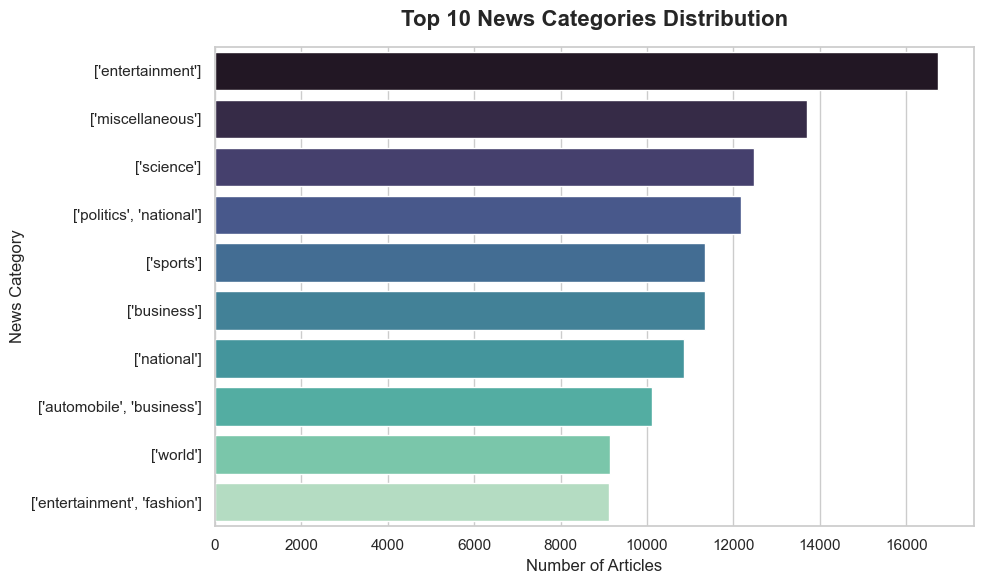

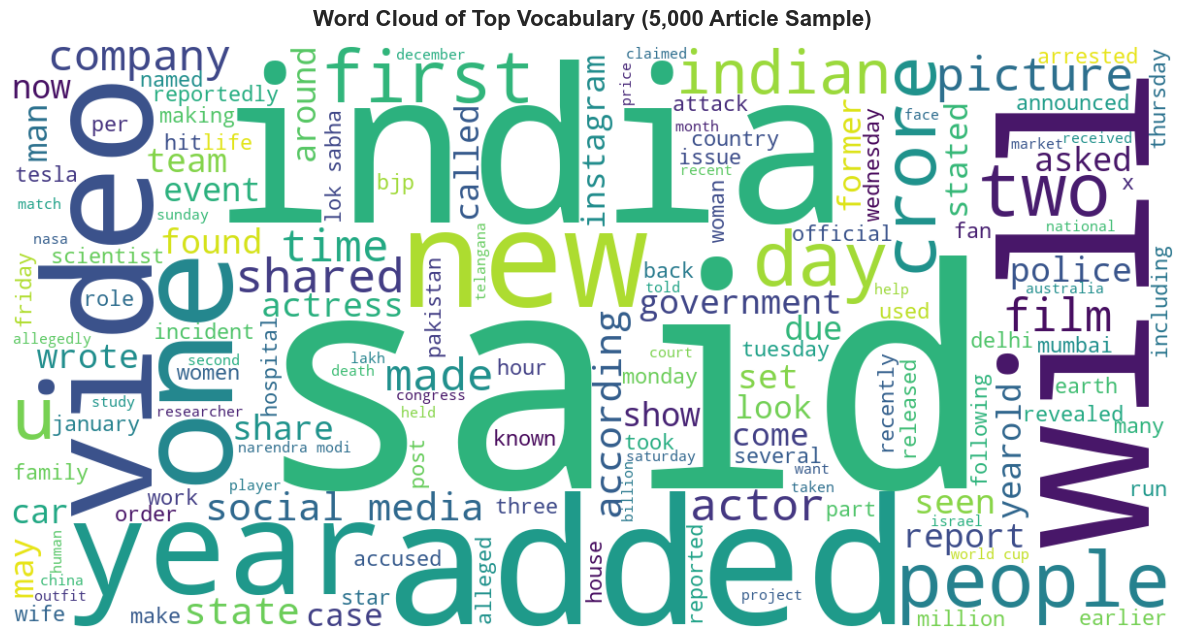

In [ ]:
# Install the wordcloud library if it's not already installed
%pip install wordcloud

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Set a cohesive visual theme for seaborn
sns.set_theme(style="whitegrid")


plt.figure(figsize=(10, 6))

# Get the value counts of the top 10 categories
category_counts = nlp_df['News Categories'].value_counts()

# Create the horizontal bar plot
sns.barplot(x=category_counts.values, y=category_counts.index, palette='mako')

# Add professional title and axis labels
plt.title('Top 10 News Categories Distribution', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Number of Articles', fontsize=12)
plt.ylabel('News Category', fontsize=12)

# Display the chart
plt.tight_layout()
plt.show()



plt.figure(figsize=(12, 8))

# Randomly sample 5,000 rows to save memory and processing time
# We use random_state=42 for reproducibility
sample_df = nlp_df.sample(n=5000, random_state=42)

# Combine all the text from the sampled rows into one giant string
text_corpus = " ".join(sample_df['cleaned_content'].tolist())

# Generate the word cloud
wordcloud = WordCloud(
    width=1200, 
    height=600, 
    background_color='white', 
    colormap='viridis',
    max_words=150
).generate(text_corpus)

# Display the word cloud
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Word Cloud of Top Vocabulary (5,000 Article Sample)', fontsize=16, fontweight='bold', pad=15)
plt.axis('off') # Hide the axes since they don't mean anything for a word cloud

# Display the chart
plt.tight_layout()
plt.show()


C:\Users\prasi\AppData\Local\Temp\ipykernel_9472\2318253054.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_15_bigrams, x='Frequency', y='Bigram', palette='magma')


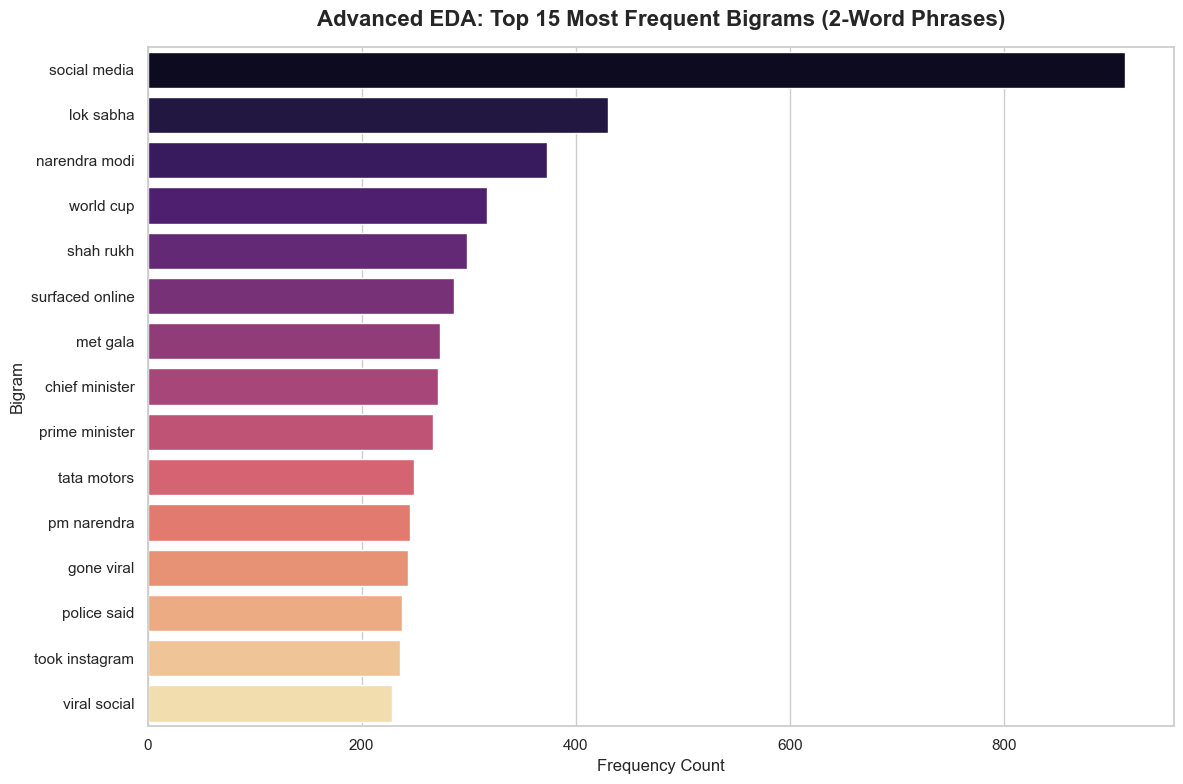

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Take a random sample of 20,000 rows to ensure fast computation
sample_texts = nlp_df['cleaned_content'].sample(n=20000, random_state=42)

# 2. Initialize CountVectorizer to find Bigrams (2-word phrases), removing English stop words
vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words='english')

# 3. Fit and transform the text data into a matrix of bigram counts
bigram_matrix = vectorizer.fit_transform(sample_texts)

# 4. Sum up the counts of each bigram across all sampled articles
bigram_sums = bigram_matrix.sum(axis=0)

# 5. Map the summed counts back to the actual bigram words
# vectorizer.vocabulary_ provides a dictionary of {word: index}
bigram_freq = [(word, bigram_sums[0, idx]) for word, idx in vectorizer.vocabulary_.items()]

# 6. Create a DataFrame, sort it by frequency, and grab the Top 15
bigram_df = pd.DataFrame(bigram_freq, columns=['Bigram', 'Frequency'])
top_15_bigrams = bigram_df.sort_values(by='Frequency', ascending=False).head(15)


# Chart: Bigram Frequency Bar Chart
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# Create a horizontal bar plot using the 'magma' palette
sns.barplot(data=top_15_bigrams, x='Frequency', y='Bigram', palette='magma')

# Add professional title and axis labels
plt.title('Advanced EDA: Top 15 Most Frequent Bigrams (2-Word Phrases)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Frequency Count', fontsize=12)
plt.ylabel('Bigram', fontsize=12)

# Ensure layout is neat and display
plt.tight_layout()
plt.show()


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Define Features (X) and Labels (y_text)
X = nlp_df['cleaned_content']
y_text = nlp_df['News Categories']

# 2. Encode the text labels into numerical targets (y)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

# Save and display the encoder mapping so we know which number equals which category
label_mapping = dict(zip(range(len(label_encoder.classes_)), label_encoder.classes_))
print("--- Label Encoder Mapping ---")
for num, category in label_mapping.items():
    print(f"{num}: {category}")
print("-" * 50)

# 3. Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize TfidfVectorizer limiting to the top 5,000 most important words
tfidf_vectorizer = TfidfVectorizer(max_features=5000)

# 5. Fit & Transform the training text
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# 6. ONLY Transform the testing text (prevents data leakage)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# 7. Print the exact shapes of the resulting TF-IDF matrices
print("-- TF-IDF Matrix Shapes --")
print(f"X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"X_test_tfidf shape:  {X_test_tfidf.shape}")


--- Label Encoder Mapping ---
0: ['automobile', 'business']
1: ['business']
2: ['entertainment', 'fashion']
3: ['entertainment']
4: ['miscellaneous']
5: ['national']
6: ['politics', 'national']
7: ['science']
8: ['sports']
9: ['world']
--------------------------------------------------
-- TF-IDF Matrix Shapes --
X_train_tfidf shape: (93585, 5000)
X_test_tfidf shape:  (23397, 5000)


In [21]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the Multinomial Naive Bayes model
nb_model = MultinomialNB()

# 2. Train the model using the TF-IDF training data
nb_model.fit(X_train_tfidf, y_train)

# 3. Generate predictions on the unseen test set
y_pred = nb_model.predict(X_test_tfidf)

# 4. Calculate and print the overall Accuracy Score as a percentage
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy Score: {accuracy * 100:.2f}%\n")

# 5. Print the detailed Classification Report
print("Classification Report:")

# Note: Since we used a LabelEncoder in the previous step, passing `target_names=label_encoder.classes_` 
# translates the 0-9 numbers back into readable category names (like "Sports" or "Politics") in the report!
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Overall Accuracy Score: 85.65%

Classification Report:
                              precision    recall  f1-score   support

  ['automobile', 'business']       0.96      0.95      0.95      2007
                ['business']       0.87      0.87      0.87      2243
['entertainment', 'fashion']       0.97      0.97      0.97      1821
           ['entertainment']       0.87      0.93      0.90      3294
           ['miscellaneous']       0.80      0.67      0.73      2818
                ['national']       0.62      0.68      0.65      2228
    ['politics', 'national']       0.78      0.87      0.82      2430
                 ['science']       0.93      0.97      0.95      2432
                  ['sports']       0.97      0.92      0.94      2242
                   ['world']       0.88      0.76      0.81      1882

                    accuracy                           0.86     23397
                   macro avg       0.86      0.86      0.86     23397
                weighted avg     

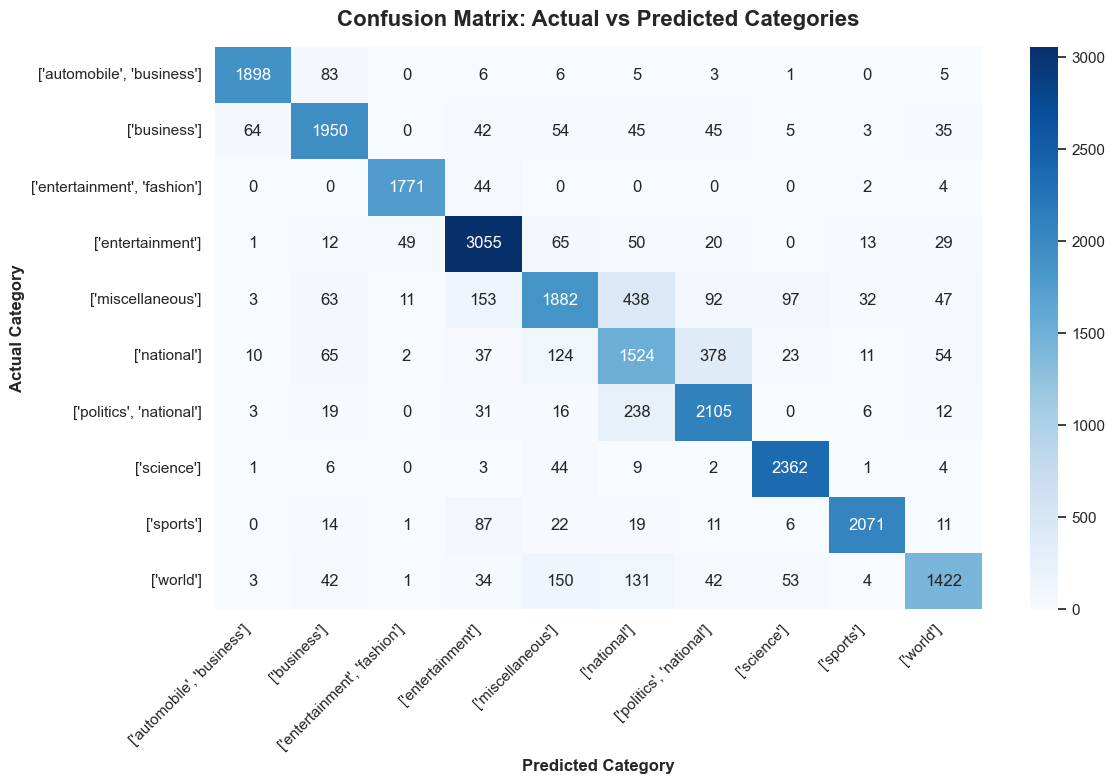

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Set up the matplotlib figure
plt.figure(figsize=(12, 8))

# 3. Create the heatmap
# annot=True adds the numbers inside the boxes
# fmt='d' formats the numbers as integers instead of scientific notation
# cmap='Blues' provides a clean, readable color gradient
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=label_encoder.classes_, 
    yticklabels=label_encoder.classes_
)

# 4. Add professional title and labels
plt.title('Confusion Matrix: Actual vs Predicted Categories', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicted Category', fontsize=12, fontweight='bold')
plt.ylabel('Actual Category', fontsize=12, fontweight='bold')

# Rotate the x-axis labels so they don't overlap
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Ensure everything fits nicely
plt.tight_layout()
plt.show()


In [28]:
def predict_news_category(text):
    """
    Takes a raw news headline/content, processes it, and predicts its category.
    """
    # 1. Clean the text (lowercase it)
    # Note: If you used the custom clean_text() function with regex earlier, 
    # you can replace this line with `cleaned_text = clean_text(text)` for even better accuracy!
    cleaned_text = text.lower()
    
    # 2. Vectorize the text using the trained TF-IDF vectorizer
    # We place the text inside a list because .transform() expects an iterable of documents
    vectorized_text = tfidf_vectorizer.transform([cleaned_text])
    
    # 3. Predict the category using the trained Naive Bayes model
    predicted_label = nb_model.predict(vectorized_text)
    
    # 4. Convert the predicted number back into the actual category string
    # We use [0] to extract the string from the resulting array
    predicted_category = label_encoder.inverse_transform(predicted_label)[0]
    
    return predicted_category

# Testing the Live Inference Function

headline_1 = "The Indian Space Research Organisation successfully launched the new rover to the moon."
headline_2 = "The stock market crashed today after the tech sector reported massive losses."
headline_3 = "The famous anime creator announced a new season of the show releasing next year."

print("--- Live AI Router Predictions ---")
print(f"Headline: '{headline_1}'")
print(f"Predicted Category: {predict_news_category(headline_1)}\n")

print(f"Headline: '{headline_2}'")
print(f"Predicted Category: {predict_news_category(headline_2)}\n")

print(f"Headline: '{headline_3}'")
print(f"Predicted Category: {predict_news_category(headline_3)}")



--- Live AI Router Predictions ---
Headline: 'The Indian Space Research Organisation successfully launched the new rover to the moon.'
Predicted Category: ['science']

Headline: 'The stock market crashed today after the tech sector reported massive losses.'
Predicted Category: ['business']

Headline: 'The famous anime creator announced a new season of the show releasing next year.'
Predicted Category: ['entertainment']


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the Logistic Regression model
# We increase max_iter to 1000 to ensure the model has enough time to converge on this large vocabulary
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Train the model using the TF-IDF training data
print("Training Logistic Regression model (this may take a few moments)...")
lr_model.fit(X_train_tfidf, y_train)

# 3. Generate predictions on the unseen test set
y_pred_lr = lr_model.predict(X_test_tfidf)

# 4. Calculate and print the overall Accuracy Score
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"\nOverall Accuracy Score (Logistic Regression): {accuracy_lr * 100:.2f}%\n")

# 5. Print the detailed Classification Report
print("=" * 50)
print("Classification Report (Logistic Regression):")
print("=" * 50)
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))


Training Logistic Regression model (this may take a few moments)...

Overall Accuracy Score (Logistic Regression): 91.70%

Classification Report (Logistic Regression):
                              precision    recall  f1-score   support

  ['automobile', 'business']       0.98      0.99      0.98      2007
                ['business']       0.92      0.93      0.93      2243
['entertainment', 'fashion']       0.99      1.00      0.99      1821
           ['entertainment']       0.96      0.96      0.96      3294
           ['miscellaneous']       0.84      0.86      0.85      2818
                ['national']       0.77      0.72      0.74      2228
    ['politics', 'national']       0.86      0.90      0.88      2430
                 ['science']       0.97      0.99      0.98      2432
                  ['sports']       0.97      0.95      0.96      2242
                   ['world']       0.91      0.87      0.89      1882

                    accuracy                           0.92 

In [30]:
def predict_news_category_lr(text):
    """
    Takes a raw news headline/content, processes it, and predicts its category
    using the Logistic Regression model.
    """
    # 1. Clean the text
    cleaned_text = text.lower()
    
    # 2. Vectorize the text using the trained TF-IDF vectorizer
    vectorized_text = tfidf_vectorizer.transform([cleaned_text])
    
    # 3. Predict the category using the trained LOGISTIC REGRESSION model
    predicted_label = lr_model.predict(vectorized_text)
    
    # 4. Convert the predicted number back into the actual category string
    predicted_category = label_encoder.inverse_transform(predicted_label)[0]
    
    return predicted_category

# Test it out!
test_headline = "The central bank decided to increase interest rates to combat inflation."
print(f"Headline: '{test_headline}'")
print(f"Predicted Category: {predict_news_category_lr(test_headline)}")


Headline: 'The central bank decided to increase interest rates to combat inflation.'
Predicted Category: ['business']


In [31]:
import joblib

# Save the Logistic Regression model
joblib.dump(lr_model, 'lr_news_model.pkl')

# Save the TF-IDF Vectorizer
joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')

# Save the Label Encoder
joblib.dump(label_encoder, 'label_encoder.pkl')

print("Successfully saved the model, vectorizer, and label encoder to disk!")


Successfully saved the model, vectorizer, and label encoder to disk!
